# Analyze yeast-GEM (version 9.1.0) SGKO results (*Saccharomyces cerevisiae*)

### Simulation conditions:
- Variants of the genome-scale metabolic model yeast-GEM version 9.1.0 (Zhang et al., 2024) have been constructed under consideration of essential and deleterious genes, as described at other sources. Variants include modified FBA models, enzyme constraint GECKO models (Sanchez et al., 2019), resource balance constraint RBA models and models with detailed thermodynamics (Salvy et al. 2019).
- FBA and GECKO models are also subjected to MOMA (Segre et al., 2002) and ROOM (Shlomi et al., 2005) methods.
- YPD rich medium has been adjusted to improve predictions of SGKOs (single gene knockouts)
- The biomass objective function (BOF) 'Growth' has been accordingly adjusted.
- The genetic background of strain BY4743: MATa/MATα his3Δ1/his3Δ1 leu2Δ0/leu2Δ0 met15Δ0/MET15 lys2Δ0/LYS2 ura3Δ0/ura3Δ0 has been set.
- A gene is considered computationally essential (for growth on YPD medium), if deletion of the gene reduces optimal growth rate to less than 0.05 h-1
- Essential and viable genes have been downloaded from BioCyc (Karp et al., 2017). Classifications are based on YKO collection (Giaever et al., 2002) with updated (Giaever and Nislow, 2014) and (Chen et al., 2012).
- The dataset of deleterious genes is based on YKO collection experimental measurements (Deutschbauer et al., 2005).
- Simulation results are augmented with data from proteomics (Bjoerkeroth et al. 2020) and UniProt (UniProt_Consortium, 2025).
- Model simulations were performed under Python 3.13, using f2xba (version 1.11.0) with Gurobi (version 13.0.3) as numerical solver.

### References:
- Björkeroth, J., Campbell, K., Malina, C., Yu, R., Di Bartolomeo, F., & Nielsen, J. (2020). Proteome reallocation from amino acid biosynthesis to ribosomes enables yeast to grow faster in rich media. Proceedings of the National Academy of Sciences, 117(35), 21804-21812. https://doi.org/10.1073/pnas.1921890117 
- Chen, W.-H., Minguez, P., Lercher, M. J., & Bork, P. (2012). OGEE: an online gene essentiality database. Nucleic Acids Research, 40(D1), D901-D906. https://doi.org/10.1093/nar/gkr986 
- Deutschbauer, A. M., Jaramillo, D. F., Proctor, M., Kumm, J., Hillenmeyer, M. E., Davis, R. W., Nislow, C., & Giaever, G. (2005). Mechanisms of Haploinsufficiency Revealed by Genome-Wide Profiling in Yeast. Genetics, 169(4), 1915-1925. https://doi.org/10.1534/genetics.104.036871 
- Giaever, G., Chu, A. M., Ni, L., Connelly, C., Riles, L., Véronneau, S., Dow, S., Lucau-Danila, A., Anderson, K., André, B., Arkin, A. P., Astromoff, A., El Bakkoury, M., Bangham, R., Benito, R., Brachat, S., Campanaro, S., Curtiss, M., Davis, K.,…Johnston, M. (2002). Functional profiling of the Saccharomyces cerevisiae genome. Nature, 418(6896), 387-391. https://doi.org/10.1038/nature00935 
- Giaever, G., & Nislow, C. (2014). The Yeast Deletion Collection: A Decade of Functional Genomics. Genetics, 197(2), 451-465. https://doi.org/10.1534/genetics.114.161620 
- Goelzer, A., & Fromion, V. (2011). Bacterial growth rate reflects a bottleneck in resource allocation. Biochimica et Biophysica Acta (BBA) - General Subjects, 1810(10), 978-988. https://doi.org/https://doi.org/10.1016/j.bbagen.2011.05.014 
- Karp, P. D., Billington, R., Caspi, R., Fulcher, C. A., Latendresse, M., Kothari, A., Keseler, I. M., Krummenacker, M., Midford, P. E., Ong, Q., Ong, W. K., Paley, S. M., & Subhraveti, P. (2017). The BioCyc collection of microbial genomes and metabolic pathways. Briefings in Bioinformatics, 20(4), 1085-1093. https://doi.org/10.1093/bib/bbx085 -
- Salvy, P., Fengos, G., Ataman, M., Pathier, T., Soh, K. C., & Hatzimanikatis, V. (2019). pyTFA and matTFA: a Python package and a Matlab toolbox for Thermodynamics-based Flux Analysis. Bioinformatics, 35(1), 167-169. https://doi.org/10.1093/bioinformatics/bty499 
- Sánchez, B. J., Zhang, C., Nilsson, A., Lahtvee, P. J., Kerkhoven, E. J., & Nielsen, J. (2017). Improving the phenotype predictions of a yeast genome‐scale metabolic model by incorporating enzymatic constraints. Molecular Systems Biology, 13(8), MSB167411. https://doi.org/10.15252/msb.20167411 
- Segrè, D., Vitkup, D., & Church, G. M. (2002). Analysis of optimality in natural and perturbed metabolic networks. Proceedings of the National Academy of Sciences, 99(23), 15112-15117. https://doi.org/10.1073/pnas.232349399 
- Shlomi, T., Berkman, O., & Ruppin, E. (2005). Regulatory on/off minimization of metabolic flux changes after genetic perturbations. Proceedings of the National Academy of Sciences, 102(21), 7695-7700. https://doi.org/10.1073/pnas.0406346102 
- UniProt_Consortium. (2025). UniProt: the Universal Protein Knowledgebase in 2025. Nucleic Acids Res, 53(D1), D609-d617. https://doi.org/10.1093/nar/gkae1010 
- Zhang, C., Sánchez, B. J., Li, F., Eiden, C. W. Q., Scott, W. T., Liebal, U. W., Blank, L. M., Mengers, H. G., Anton, M., Rangel, A. T., Mendoza, S. N., Zhang, L., Nielsen, J., Lu, H., & Kerkhoven, E. J. (2024). Yeast9: a consensus genome-scale metabolic model for S. cerevisiae curated by the community. Molecular Systems Biology, 20(10), 3. https://doi.org/10.1038/s44320-024-00060-7 

Peter Schubert, Heinrich-Heine University Duesseldorf, Institute for Computational Cell Biology (M. Lercher), Nov 11, 2026

In [1]:
import re
import os
import time
import numpy as np
import pandas as pd

from scipy.stats import pearsonr, spearmanr

import matplotlib.pyplot as plt
import matplotlib as mpl

from f2xba.uniprot.uniprot_data import UniprotData
from f2xba.utils.sgko_utils import confusion_matrix, export_gene_predictions

pd.set_option('io.excel.xlsx.reader', 'calamine')

# directories and model names
sbml_dir = 'SBML_models/yeast910'
ref_data_dir = 'data_refs/yeast910'
plots_dir = 'plots/yeast910'
results_dir = 'results/yeast910'

organism_id = 559292
reference_cond = 'glc_rich_anaerobic'

proteomics_fname = 'Yeast_Bjoerkeroth_proteomics_merged.xlsx'
yeast_ess_genes_fname = 'BioCyc_essentiality_S288c_1049-All-Genes-from-a-list.txt'
yeast_via_genes_fname = 'BioCyc_essentiality_S288c_4486-All-Genes-from-a-list.txt'
yeast_del_genes_fname = 'Deutschbauer_2005_yeast_deleterious_genes.txt'
yko_homodipl_genes_fname = 'strain_homozygous_diploid.txt'

try:
    plt.style.use('CCB_plot_style_0v4_2')
except OSError:
    print('using standard matplotlib styles')

print(f'working directory: {os.getcwd()}')

working directory: /Users/peter/Documents/CCB/work/projects/DeleteriousGenes/notebooks


In [2]:
sgko_simulations = ['yeast910_FBA', 'yeast910_FBA_MOMA', 'yeast910_FBA_lMOMA', 'yeast910_FBA_ROOM', 'yeast910_FBA_lROOM',    
                    'yeast910_TurNuP_GECKO',
                    'yeast910_GECKO', 'yeast910_GECKO_MOMA', 'yeast910_GECKO_ROOM', # 'yeast910_GECKO_lMOMA', 'yeast910_GECKO_lROOM',
                    'yeast910_RBA',  
                    'yeast910_TFA',
                    'yeast910_TGECKO', 'yeast910_TRBA'
                   ]

In [3]:
# load proteomics data
fname = os.path.join(ref_data_dir, proteomics_fname)
with pd.ExcelFile(fname) as xlsx:
    df_mpmf = pd.read_excel(xlsx, sheet_name='proteomics', index_col=0)
    print(f'{len(df_mpmf)} records of proteomics loaded from {fname}')

# load Uniprot data
uniprot_data = UniprotData(organism_id, ref_data_dir)

# load YKO gene essentiality data from BioCyc extract (Giaever et al., 2014, Chen at al., 2012, YDP)
fname = os.path.join(ref_data_dir, yeast_ess_genes_fname)
yko_ess_genes = set(pd.read_table(fname)['Accession-1'].values)
fname = os.path.join(ref_data_dir, yeast_via_genes_fname)
yko_via_genes = set(pd.read_table(fname)['Accession-1'].values)
print(f'{len(yko_ess_genes)} essential genes and {len(yko_via_genes)} viable genes extracted from BioCyc data.')

# load YKO deleterious genes from Deutschbauer, 2005
fname = os.path.join(ref_data_dir, yeast_del_genes_fname)
df = pd.read_table(fname, index_col=0)
del_genes_fitness = df['HOM_AV'].to_dict()
print(f'{len(del_genes_fitness)} deleterious genes extracted from Deutschbauer, 2005')

# load YKO homozygous strains from Giaever, 2002
fname = os.path.join(ref_data_dir, yko_homodipl_genes_fname)
df = pd.read_table(fname, index_col=0)
yko_hom_genes = {gene.strip() for gene in df[1:]['ORF_name'].values}
print(f'{len(yko_hom_genes)} genes from YKO homozygous diploid strain, Giaever, 2002')
inconsistant_gene_class = yko_hom_genes.intersection(yko_ess_genes)
yko_hom_genes -= inconsistant_gene_class
print(f'{inconsistant_gene_class} removed from YKO homozygous diploid genes, as already part of essential genes.')

3667 records of proteomics loaded from data_refs/yeast910/Yeast_Bjoerkeroth_proteomics_merged.xlsx
extracting UniProt protein data from data_refs/yeast910/uniprot_organism_559292.tsv
1049 essential genes and 4486 viable genes extracted from BioCyc data.
891 deleterious genes extracted from Deutschbauer, 2005
4939 genes from YKO homozygous diploid strain, Giaever, 2002
{'YBR038W'} removed from YKO homozygous diploid genes, as already part of essential genes.


## Load datasets
- load results from single gene knockout simulations (13 methods/models)
- load essential genes (YKO homozygous collection (Giaver et al., 2002; Giaever et al., 2014))
- load genes with deleterious effects (Deutschbauer et al., 2005)

In [4]:
# load predicted sgko results: - updated
all_genes = {}
sgko_predictions = {}
for idx, method_name in enumerate(sgko_simulations):
    fname = os.path.join(results_dir, f'sgko_{method_name}.xlsx')
    if os.path.exists(fname):
        with pd.ExcelFile(fname) as xlsx:
            df_sgko = pd.read_excel(xlsx, sheet_name='sgko', index_col=0)
        wt_gr = df_sgko.at['wt', 'growth_rate']
        genes = {gene for gene in df_sgko.index if gene != 'wt'}
        df = df_sgko.loc[sorted(genes)]
        redundant = sum(df['status'] == 'wt_solution')
        sgko_predictions[method_name] = df
        all_genes[method_name] = genes
        print(f'{idx+1:2d}: {method_name:21s} wt gr: {wt_gr:5.3f}h-1 ({len(genes):4d} genes - '
              f'{redundant:4d} inactive in wt) {time.ctime(os.path.getmtime(fname))}')
    else:
        print(f'{idx+1:2d}: {fname} not found')
common_pred_genes = all_genes[sgko_simulations[0]]
for method_name in all_genes:
    common_pred_genes = common_pred_genes.intersection(all_genes[method_name])
print(f'{len(common_pred_genes)} common genes shared by model simulations')

 1: yeast910_FBA          wt gr: 0.441h-1 (1156 genes -  542 inactive in wt) Wed Nov  4 12:51:54 2026
 2: yeast910_FBA_MOMA     wt gr: 0.441h-1 (1156 genes -  540 inactive in wt) Wed Nov  4 10:27:59 2026
 3: yeast910_FBA_lMOMA    wt gr: 0.441h-1 (1156 genes -  540 inactive in wt) Wed Nov  4 10:24:42 2026
 4: yeast910_FBA_ROOM     wt gr: 0.441h-1 (1156 genes -  540 inactive in wt) Wed Nov  4 12:51:53 2026
 5: yeast910_FBA_lROOM    wt gr: 0.441h-1 (1156 genes -  540 inactive in wt) Wed Nov  4 10:30:53 2026
 6: yeast910_TurNuP_GECKO wt gr: 0.527h-1 (1145 genes -  735 inactive in wt) Wed Nov  4 12:53:54 2026
 7: yeast910_GECKO        wt gr: 0.516h-1 (1145 genes -  706 inactive in wt) Wed Nov  4 15:53:17 2026
 8: yeast910_GECKO_MOMA   wt gr: 0.516h-1 (1145 genes -  705 inactive in wt) Wed Nov  4 13:06:54 2026
 9: yeast910_GECKO_ROOM   wt gr: 0.516h-1 (1145 genes -  705 inactive in wt) Wed Nov  4 15:53:17 2026
10: yeast910_RBA          wt gr: 0.503h-1 (1384 genes -  704 inactive in wt) Wed N

# Yeast Knockout deletion collections YKO

The YKO collection has between created between 1998 and 2002 by the Saccharomyces Genome Deletion Project (Giaever et al., 2002; Giaever et al., 2014 )]. It consists of > 21000 mutant strains, derived from yeast strain S228c, the strain which has been used in the yeast genome sequencing project. Mutants carry single gene deletions of the non-essential genes. Individual genes were replaced by precise start-to-stop deletions of ~6000 ORFs and replacement with KanMX4 (kanamycin selection marker), with two distinct 20-nucleotide sequences serving as molecular bar codes. The mutant library consists of homozygous diploids, heterozygous diploids, haploids of MATa and MATα. YPD medium is used for growth.

|Strain   | Background | Genotype |
|---------|------------|----------|
|MATa     | BY4730 | MATa leu2Δ0 met15Δ0 ura3Δ0 |
|MATalpha |	BY4739 | MATalpha leu2Δ0 lys2Δ0 ura3Δ0 |
|MATa     | BY4741 | MATa his3Δ1 leu2Δ0 met15Δ0 ura3Δ0 |
|MATalpha | BY4742 | MATalpha his3Δ1 leu2Δ0 lys2Δ0 ura3Δ0 |
|Het/Hom diploid | BY4743 |4741/4742|

### Homozygous diploid collection

The homozygous diploid collection is the recommended collection in experiments, as it can avoid many inconsistencies (Giaever et al., 2014). Its genetic background is BY4743: MATa/MATα his3Δ1/his3Δ1 leu2Δ0/leu2Δ0 met15Δ0/MET15 lys2Δ0/LYS2 ura3Δ0/ura3Δ0 containing the auxotrophic marker mutations: his3Δ1/YOR202W, leu2Δ0/YCL018W, ura3Δ0/YEL021W. For this study, we performed some corrections relating to gene identification and classification. YHR039C-B is renamed to YHR039C-A (VMA10, H(+)-transporting V1 sector ATPase subunit G, see BioCyc) and YBR038W (CHS2, chitin synthase 2) is removed from the homozygous strains, as it is included in essential genes

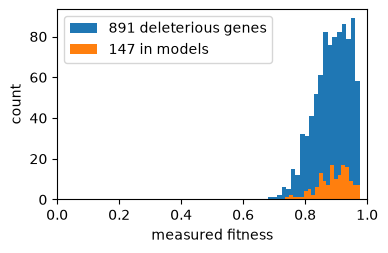

In [5]:
# plot dataset of deleterious genes
del_model_genes_fitness = {gene: fitness for gene, fitness in del_genes_fitness.items() if gene in common_pred_genes}

fig, axs = plt.subplots(1, 1, figsize=(4.0, 4.0 * .618), squeeze=False)
ax = axs[0, 0]
ax.hist(del_genes_fitness.values(), bins=20, linewidth=0.5, label=f'{len(del_genes_fitness)} deleterious genes')
ax.hist(del_model_genes_fitness.values(), bins=20, linewidth=0.5, label=f'{len(del_model_genes_fitness)} in models')
ax.set_ylabel(r'count')
ax.set_xlabel(r'measured fitness')
ax.legend(loc='upper left')
ax.set(xlim=(0.0, 1.0))
#fig.savefig(f'{plots_dir}/SGKO_deleterious_genes.pdf')
plt.show()

### essential genes analysis

In [6]:
# gene essentiality analysis wrt extended models

pred_ess_thr = 0.05
method_name = 'yeast910_RBA'

exp_classification = {gene: False for gene in yko_via_genes}
exp_classification.update({gene: True for gene in yko_ess_genes})
pred_classification = (sgko_predictions[method_name].loc[list(common_pred_genes)]['fitness'] < pred_ess_thr).to_dict()
pred_ess = confusion_matrix(exp_classification, pred_classification)

print(f'{method_name}: Essential gene predictions for ({len(common_pred_genes)} common genes across models)')
#print(f'Essential genes prediction by {target_model}.xml')
print(f'{len(pred_ess["tp"]) + len(pred_ess["fn"]):3d} exp essential genes (Giaever et al., 2014, Chen at al., 2012)')
print(f'{len(pred_ess["fp"]) + len(pred_ess["tn"]):3d} exp viable genes (Giaever et al., 2014, Chen at al., 2012)')
print(f'pred_ess_thr = {pred_ess_thr:.2f}')
print(f'recall:    {pred_ess["recall"]:.3f}')
print(f'precision: {pred_ess["precision"]:.3f}')
print(f'accuracy:  {pred_ess["accuracy"]:.3f}')
print(f'mcc:       {pred_ess["mcc"]:.3f}')
print(f"{pred_ess['cm'].sum().sum()} genes:")
pred_ess['cm']

yeast910_RBA: Essential gene predictions for (1145 common genes across models)
172 exp essential genes (Giaever et al., 2014, Chen at al., 2012)
919 exp viable genes (Giaever et al., 2014, Chen at al., 2012)
pred_ess_thr = 0.05
recall:    0.890
precision: 0.944
accuracy:  0.974
mcc:       0.902
1091 genes:


,pred_pos,pred_neg
act_pos,153,19
act_neg,9,910


#### 'best' essential genes predictions:

<p> 
yeast910_GECKO: Essential gene predictions for (1148 common genes across models) <br/>
172 exp essential genes (Giaever et al., 2014, Chen at al., 2012) <br/>
922 exp viable genes (Giaever et al., 2014, Chen at al., 2012) <br/>
pred_ess_thr = 0.05 <br/>
recall: &nbsp; &nbsp; &nbsp; &nbsp; 0.890 <br/>
precision: &nbsp; 0.944 <br/>
accuracy: &nbsp; 0.974 <br/>
mcc: &nbsp; &nbsp; &nbsp; &nbsp; &nbsp; 0.902 <br/></p>
<table align='left'>
    <tr>
        <th></td>
        <th>pred_ess</td>
        <th>pred_via</td></tr>
    <tr>
        <td>exp_ess</td>
        <td align='right'>153</td>
        <td align='right'>19</td></tr>
    <tr>
        <td>exp_via</td>
        <td align='right'>9</td>
        <td align='right'>913</td></tr>    
</table>

In [7]:
# export essential predictions
df_sgko = sgko_predictions[method_name].loc[list(common_pred_genes)]
pred_fitness = df_sgko['fitness'].to_dict()
pred_status = df_sgko['status'].to_dict()
exp_mpmf = df_mpmf['glc_rich_aerobic'].to_dict()
fname = os.path.join(results_dir, f'{method_name}_ess_predictions.xlsx')
df_predictions = export_gene_predictions(pred_ess, {}, pred_fitness, pred_status, uniprot_data, exp_mpmf, fname)
n_false_predictions = len(df_predictions[df_predictions['prediction'].str.startswith('f')])
print(f'{n_false_predictions} false predictions')
df_predictions.head(3)

prediction results written to results/yeast910/yeast910_RBA_ess_predictions.xlsx
28 false predictions


,gene_name,prediction,pred_fitness,pred_status,exp_fitness,mpmf,uid,aa_len,description,go_processes
gene,,,,,,,,,,
Q0045,COX1,tn,0.940426,optimal,None,0.034553,P00401,534,Cytochrome c oxidase subunit 1,aerobic respiration; cellular respiration; mit...
Q0080,ATP8,tn,0.952475,optimal,None,NaN,P00856,48,ATP synthase protein 8,proton motive force-driven ATP synthesis
Q0085,ATP6,tn,0.952475,optimal,None,NaN,P00854,259,ATP synthase subunit a,proton motive force-driven ATP synthesis


### deleterious genes analysis

In [8]:
# deleterious genes analysis
exp_del_thr = 0.945
pred_del_thr = 0.985
method_name = 'yeast910_GECKO'

exp_classification = {gene: del_genes_fitness.get(gene, 1.0) < exp_del_thr for gene in yko_hom_genes}
pred_classification = (sgko_predictions[method_name].loc[list(common_pred_genes)]['fitness'] < pred_del_thr).to_dict()
pred_del = confusion_matrix(exp_classification, pred_classification)

print(f'{method_name}: Deleterious gene predictions for ({len(common_pred_genes)} common genes across models)')
print(f'exp_del_thr = {exp_del_thr:.3f}, pred_del_thr = {pred_del_thr:.3f}')
print(f'{len(pred_del["tp"]) + len(pred_del["fn"]):3d} exp deleterious (Deutschbauer, 2005), ' +
      f'{len(pred_del["fp"]) + len(pred_del["tn"]):3d} exp redundant genes (Giaever, 2002)')
print(f'exp_del_thr = {exp_del_thr:.3f}, pred_del_thr = {pred_del_thr:.3f}')
print(f'recall:    {pred_del["recall"]:.3f}')
print(f'precision: {pred_del["precision"]:.3f}')
print(f'accuracy:  {pred_del["accuracy"]:.3f}')
print(f'mcc:       {pred_del["mcc"]:.3f}')
print(f"{pred_del['cm'].sum().sum()} genes:")
pred_del['cm']

yeast910_GECKO: Deleterious gene predictions for (1145 common genes across models)
exp_del_thr = 0.945, pred_del_thr = 0.985
129 exp deleterious (Deutschbauer, 2005), 772 exp redundant genes (Giaever, 2002)
exp_del_thr = 0.945, pred_del_thr = 0.985
recall:    0.659
precision: 0.697
accuracy:  0.910
mcc:       0.625
901 genes:


,pred_pos,pred_neg
act_pos,85,44
act_neg,37,735


In [9]:
# export deleterious predictions

df_sgko = sgko_predictions[method_name].loc[list(common_pred_genes)]
pred_fitness = df_sgko['fitness'].to_dict()
pred_status = df_sgko['status'].to_dict()
exp_mpmf = df_mpmf['glc_rich_aerobic'].to_dict()
fname = os.path.join(results_dir, f'{method_name}_del_predictions.xlsx')
df_predictions = export_gene_predictions(pred_del, del_genes_fitness, pred_fitness, pred_status, uniprot_data, exp_mpmf, fname)
n_false_predictions = len(df_predictions[df_predictions['prediction'].str.startswith('f')])
print(f'{n_false_predictions} false predictions')
df_predictions.head(3)

prediction results written to results/yeast910/yeast910_GECKO_del_predictions.xlsx
81 false predictions


,gene_name,prediction,pred_fitness,pred_status,exp_fitness,mpmf,uid,aa_len,description,go_processes
gene,,,,,,,,,,
YAL012W,CYS3,tp,0.703610,optimal,0.922,0.198585,P31373,394,Cystathionine gamma-lyase,L-cysteine biosynthetic process; L-cysteine bi...
YAL022C,FUN26,tn,1.000000,wt_solution,NaN,0.002728,P31381,517,Nucleoside transporter FUN26,nicotinamide riboside transport; nucleobase tr...
YAL023C,PMT2,tp,0.984321,optimal,0.921,0.139770,P31382,759,Dolichyl-phosphate-mannose--protein mannosyltr...,ERAD pathway; fungal-type cell wall biogenesis...


### Determine optimal threshold parameters for deleterious predictions
- optimality here with respect to highest mcc (Matthews correlation coefficient)
    - scan exp_del_thrs and pred_del_thrs to find highest mcc
    - select the highest pred_del_thr value in the range of optimal pred_del_thr values

In [10]:
# deleterious SGKO analysis: determine optimal exp_del_thr and pred_pred_del_thr wrt to mcc

exp_del_thrs = [0.930, 0.935, 0.940, 0.945, 0.950, 0.955]
pred_del_thrs = [0.940, 0.945, 0.950, 0.955, 0.960, 0.965, 0.970, 0.975, 0.980, 0.985, 0.990, 0.995]

cols = ['model', 'exp_del_thr', 'mcc', 'pred_del_thrs', 'pred_del_thr', 'genes', 'TP', 'FN', 'FP', 'TN']
thrs_vs_pred = []
opt_pred_del_thrs = {}
for method_name in sgko_predictions.keys():
    
    opt_pred_del_thrs[method_name] = {}
    for exp_del_thr in exp_del_thrs:
        exp_classification = {gene: del_genes_fitness.get(gene, 1.0) < exp_del_thr for gene in yko_hom_genes}
        max_mcc = 0.0
        best_pred_del_thr_l = pred_del_thrs[0]
        best_pred_del_thr_u = pred_del_thrs[0]
        tp = fp = fn = 0
        for pred_del_thr in pred_del_thrs:
            pred_classification = (sgko_predictions[method_name].loc[list(common_pred_genes)]['fitness'] < pred_del_thr).to_dict()
            pred = confusion_matrix(exp_classification, pred_classification)
            if pred['mcc'] > max_mcc:
                max_mcc = pred['mcc']
                best_pred_del_thr_l = pred_del_thr
                best_pred_del_thr_u = pred_del_thr
                tp, fn, fp, tn = pred['cm'].to_numpy().flatten()
                genes = pred['cm'].to_numpy().flatten().sum()
            elif pred['mcc'] == max_mcc:
                best_pred_del_thr_u = pred_del_thr
                tp, fn, fp, tn = pred['cm'].to_numpy().flatten()
                genes = pred['cm'].to_numpy().flatten().sum()
        opt_pred_del_thrs[method_name][exp_del_thr] = best_pred_del_thr_u
        thrs_vs_pred.append([method_name, exp_del_thr, max_mcc,  
                    f'[{best_pred_del_thr_l:.3f} - {best_pred_del_thr_u:.3f}]', best_pred_del_thr_u, genes, tp, fn, fp, tn])
        
        #print(f'{method_name:20s} {exp_thr} best mcc: {max_mcc:.3f} at pred_del_thrs range: '
        #      f'[{best_pred_del_thr_l:.3f} - {best_pred_del_thr_u:.3f}], {best_pred_del_thr_u:.3f}, '
        #      f'TP:{tp:2d}, FP:{fp:2d}, FN: {fn:3d}')
df_thrs_vs_pred = pd.DataFrame(thrs_vs_pred, columns=cols)
fname = os.path.join(results_dir, f'yeast910_thrs_vs_pred.xlsx')
with pd.ExcelWriter(fname) as writer:
    df_thrs_vs_pred.to_excel(writer, sheet_name='best thresholds')
    print(f'Thresholds vs. prediction results table exported to {fname}')
df_thrs_vs_pred.head()

Thresholds vs. prediction results table exported to results/yeast910/yeast910_thrs_vs_pred.xlsx


,model,exp_del_thr,mcc,pred_del_thrs,pred_del_thr,genes,TP,FN,FP,TN
0,yeast910_FBA,0.930,0.255794,[0.940 - 0.995],0.995,901,30,80,45,746
1,yeast910_FBA,0.935,0.270036,[0.940 - 0.995],0.995,901,32,83,43,743
2,yeast910_FBA,0.940,0.303477,[0.940 - 0.995],0.995,901,36,86,39,740
3,yeast910_FBA,0.945,0.312721,[0.940 - 0.995],0.995,901,38,91,37,735
4,yeast910_FBA,0.950,0.308830,[0.940 - 0.995],0.995,901,38,93,37,733


In [11]:
# SGKO result tables for given experimental threshold

exp_del_thr = 0.945
pred_ess_thr = 0.05

cols = ['exp_thr', 'pred_thr', 'total', 'tp', 'fn', 'fp', 'tn', 'recall', 'precision', 'specificity', 'accuracy', 'mcc']
results = {'ess': {}, 'del': {}}
for method_name in sgko_predictions:

    # essential genes
    exp_classification = {gene: False for gene in yko_via_genes}
    exp_classification.update({gene: True for gene in yko_ess_genes})
    pred_classification = (sgko_predictions[method_name].loc[list(common_pred_genes)]['fitness'] < pred_ess_thr).to_dict()
    pred = confusion_matrix(exp_classification, pred_classification)
    results['ess'][method_name] = ([None, pred_ess_thr, int(pred['cm'].sum().sum())] + 
                                   [len(pred[key]) for key in ['tp', 'fn', 'fp', 'tn']] +
                                   [pred[key] for key in ['recall', 'precision', 'specificity', 'accuracy', 'mcc']])

    # deleterious genes
    exp_classification = {gene: del_genes_fitness.get(gene, 1.0) < exp_del_thr for gene in yko_hom_genes}
    pred_del_thr = opt_pred_del_thrs[method_name][exp_del_thr]
    pred_classification = (sgko_predictions[method_name].loc[list(common_pred_genes)]['fitness'] < pred_del_thr).to_dict()
    pred = confusion_matrix(exp_classification, pred_classification)
    results['del'][method_name] = ([exp_del_thr, pred_del_thr, int(pred['cm'].sum().sum())] + 
                                   [len(pred[key]) for key in ['tp', 'fn', 'fp', 'tn']] +
                                   [pred[key] for key in ['recall', 'precision', 'specificity', 'accuracy', 'mcc']])

df_results_ess = pd.DataFrame(results['ess'].values(), index=list(results['ess']), columns=cols)
df_results_ess.index.name = 'essential'
df_results_del = pd.DataFrame(results['del'].values(), index=list(results['del']), columns=cols)
df_results_del.index.name = 'deleterious'
df_results_del

,exp_thr,pred_thr,total,tp,fn,fp,tn,recall,precision,specificity,accuracy,mcc
deleterious,,,,,,,,,,,,
yeast910_FBA,0.945,0.995,901,38,91,37,735,0.294574,0.506667,0.952073,0.857936,0.312721
yeast910_FBA_MOMA,0.945,0.990,901,70,59,83,689,0.542636,0.457516,0.892487,0.842397,0.405900
yeast910_FBA_lMOMA,0.945,0.995,901,59,70,51,721,0.457364,0.536364,0.933938,0.865705,0.418631
yeast910_FBA_ROOM,0.945,0.965,901,38,91,37,735,0.294574,0.506667,0.952073,0.857936,0.312721
yeast910_FBA_lROOM,0.945,0.995,901,38,91,37,735,0.294574,0.506667,0.952073,0.857936,0.312721
yeast910_TurNuP_GECKO,0.945,0.960,901,49,80,33,739,0.379845,0.597561,0.957254,0.874584,0.410499
yeast910_GECKO,0.945,0.985,901,85,44,37,735,0.658915,0.696721,0.952073,0.910100,0.625442
yeast910_GECKO_MOMA,0.945,0.940,901,89,40,55,717,0.689922,0.618056,0.928756,0.894562,0.591343
yeast910_GECKO_ROOM,0.945,0.965,901,72,57,33,739,0.558140,0.685714,0.957254,0.900111,0.562589


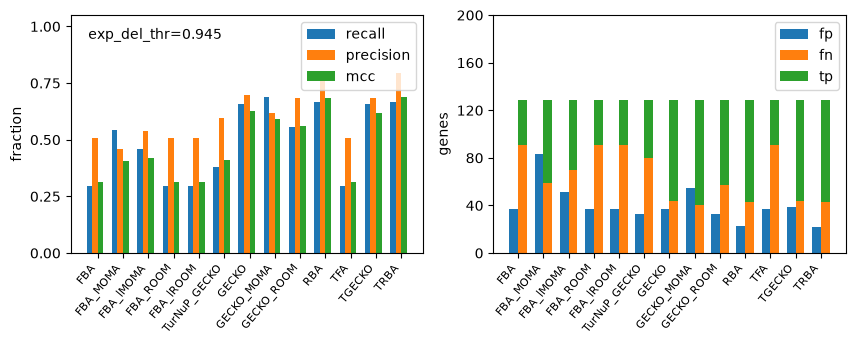

In [12]:
# plot prediction results for deleterious genes

exp_del_thr = 0.945
x = np.arange(len(df_results_del)) 

df_data = df_results_del

grid = [1, 2]   # nrows, ncols
fig, axs = plt.subplots(grid[0], grid[1], figsize=(5.0 * grid[1], 3.09 * grid[0]), squeeze=False )
for gcol in range(grid[1]):
    ax = axs[0, gcol]
    if gcol == 0:
        width = 0.22  # the width of the bars
        for col, pos in {'recall': x - 1.5*width, 'precision': x - width/2, 'mcc': x + width/2}.items():
            ax.bar(pos, df_data[col], width, label=col)
        ax.set_ylabel('fraction')
        ax.set_ylim(0.0, 1.05)
        ax.text(0.05, 0.9, f'exp_del_thr={exp_del_thr:.3f}', transform=ax.transAxes, ha='left')  
    else:             
        width = 0.35  # the width of the bars
        ax.bar(x - width/2, df_data['fp'], width, label='fp')
        ax.bar(x + width/2, df_data['fn'], width, label='fn')
        ax.bar(x + width/2, df_data['tp'], width, label='tp', bottom=df_data['fn'].values)
        ax.set_ylabel('genes')
        ax.set_ylim(0, 200)

    ax.set_xticks(x)
    ax.set_xticklabels([re.sub('yeast910_', '', method) for method in df_data.index], rotation=50, ha='right', fontsize=8)
    ax.legend(loc='upper right')
    ax.yaxis.set_major_locator(plt.MaxNLocator(nbins=5))
# fig.savefig(os.path.join(plots_dir, 'Predictions_deleterious_genes.pdf'))
plt.show()

In [13]:
fname = os.path.join(results_dir, f'yeast910_essential_gene_prediction_stats.xlsx')
with pd.ExcelWriter(fname) as writer:
    df_results_ess.to_excel(writer, sheet_name='essential genes')
    print(f'Essential genes prediction stat exported to {fname}')
df_results_ess

Essential genes prediction stat exported to results/yeast910/yeast910_essential_gene_prediction_stats.xlsx


,exp_thr,pred_thr,total,tp,fn,fp,tn,recall,precision,specificity,accuracy,mcc
essential,,,,,,,,,,,,
yeast910_FBA,None,0.05,1091,153,19,9,910,0.889535,0.944444,0.990207,0.974335,0.901596
yeast910_FBA_MOMA,None,0.05,1091,157,15,93,826,0.912791,0.628000,0.898803,0.901008,0.703708
yeast910_FBA_lMOMA,None,0.05,1091,155,17,60,859,0.901163,0.720930,0.934712,0.929423,0.765758
yeast910_FBA_ROOM,None,0.05,1091,154,18,33,886,0.895349,0.823529,0.964091,0.953254,0.831061
yeast910_FBA_lROOM,None,0.05,1091,153,19,9,910,0.889535,0.944444,0.990207,0.974335,0.901596
yeast910_TurNuP_GECKO,None,0.05,1091,153,19,9,910,0.889535,0.944444,0.990207,0.974335,0.901596
yeast910_GECKO,None,0.05,1091,153,19,9,910,0.889535,0.944444,0.990207,0.974335,0.901596
yeast910_GECKO_MOMA,None,0.05,1091,159,13,14,905,0.924419,0.919075,0.984766,0.975252,0.907047
yeast910_GECKO_ROOM,None,0.05,1091,153,19,9,910,0.889535,0.944444,0.990207,0.974335,0.901596


### ROC curves
- parameterize based on the del_pred_thr between 0.0 and 1.0
    - i.e. categorization per threshold value

In [14]:
# collect ROC stats for roc curve
# based on deleterious threshold for predictions, determine recall and FDR (1.0 - specificity)

exp_del_thr = 0.945

exp_classification = {gene: del_genes_fitness.get(gene, 1.0) < exp_del_thr for gene in yko_hom_genes}

pred_del_thrs = np.linspace(0.0, 1.0, 200+1) 
roc = {}
for method_name in sgko_predictions:

    recall_vals = np.zeros(len(pred_del_thrs))
    fdr_vals = np.zeros(len(pred_del_thrs))
    mcc_vals = np.zeros(len(pred_del_thrs))
    
    for idx, pred_del_thr in enumerate(pred_del_thrs):
        pred_classification = (sgko_predictions[method_name].loc[list(common_pred_genes)]['fitness'] < pred_del_thr).to_dict()
        pred = confusion_matrix(exp_classification, pred_classification)
        recall_vals[idx] = pred['recall']
        fdr_vals[idx] = 1.0 - pred['specificity']
        mcc_vals[idx] = pred['mcc']
    roc[method_name] = {'pred_del_thrs': pred_del_thrs, 'recall': recall_vals, 'FDR': fdr_vals, 'mcc': mcc_vals}
print('Done!')

Done!


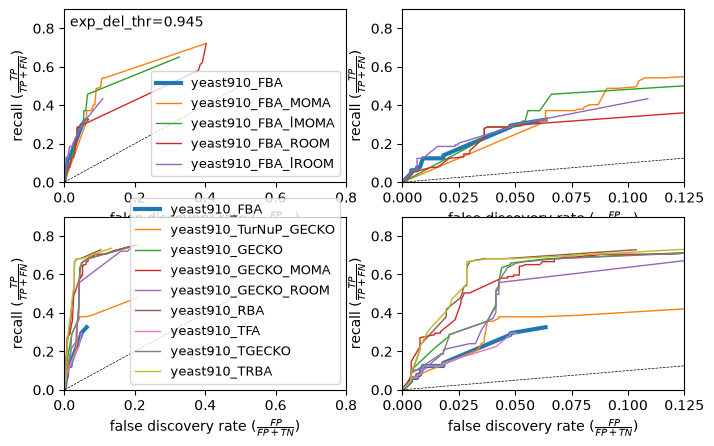

In [15]:
# plot roc curves
grid = [len(sgko_simulations), 1]

grid = [2, 2]
fig, axs = plt.subplots(nrows=grid[0], ncols=grid[1], figsize=(grid[1] * 4.0, grid[0] *4.0 * .618), squeeze=False)
for row in range(grid[0]):
    if row == 0:
        method_names = ['yeast910_FBA', 'yeast910_FBA_MOMA', 'yeast910_FBA_lMOMA', 'yeast910_FBA_ROOM', 'yeast910_FBA_lROOM']
    else:
        method_names = ['yeast910_FBA', 'yeast910_TurNuP_GECKO', 'yeast910_GECKO', 'yeast910_GECKO_MOMA', 'yeast910_GECKO_ROOM', 
                        'yeast910_RBA', 'yeast910_TFA', 'yeast910_TGECKO', 'yeast910_TRBA']
    for col in range(grid[1]):
        ax=axs[row, col] 

        if row == 1 and col == 2:
            method_names = ['yeast910_FBA', 'yeast910_GECKO', 'yeast910_GECKO_MOMA', 'yeast910_GECKO_ROOM', 
                            'yeast910_RBA']        

        for method_name in method_names:
            lw = 3.0 if method_name == 'yeast910_FBA' else 1.0
            ax.plot(roc[method_name]['FDR'], roc[method_name]['recall'], marker='', lw=lw, label=method_name)
        ax.plot((0.0, 0.5),(0.0, 0.5), 'k--', lw=0.5)

        if col == 0:
            ax.legend(loc='lower right', fontsize=9.0)
            ax.set_xlim(0.0, 0.8)
            ax.set_ylim(0.0, 0.9)
        if col == 1:
            ax.set_xlim(0.0, 0.125)
            ax.set_ylim(0.0, 0.9)
        if row == 0 and col == 0:
            ax.text(0.02, 0.9, f'exp_del_thr={exp_del_thr}', transform=ax.transAxes, ha='left') 

        ax.set_xlabel(r'false discovery rate ($\frac{FP}{FP+TN}$)')
        ax.set_ylabel(r'recall ($\frac{TP}{TP+FN}$)')
# fig.savefig(f'{plots_dir}/ROC_pred_fitness_threshold.pdf')
plt.show()  

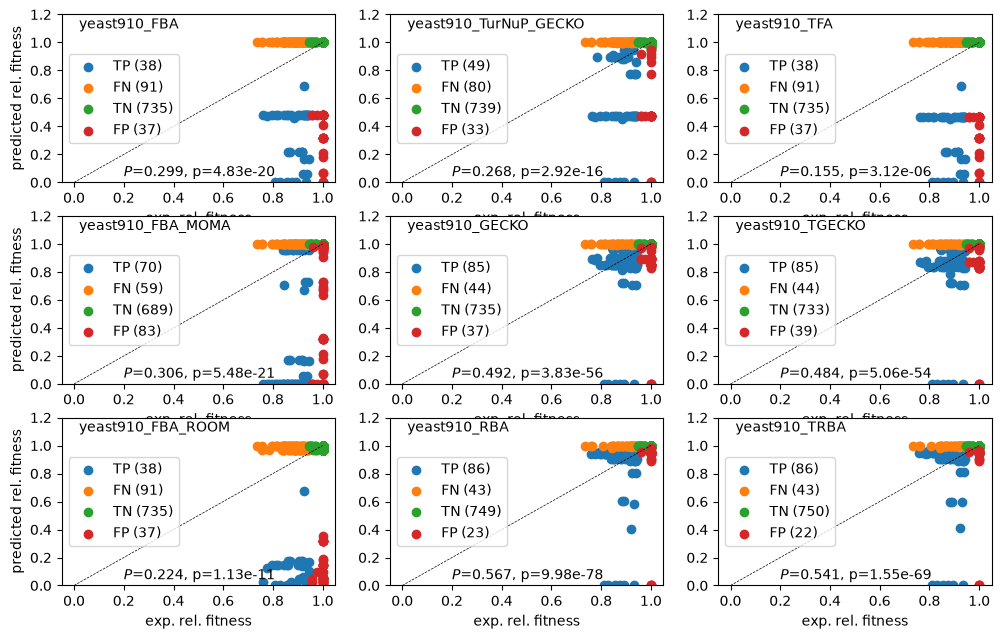

In [16]:
# plot growth rate results with colors for deleterious gene predictions

exp_del_thr = 0.945

exp_classification = {gene: del_genes_fitness.get(gene, 1.0) < exp_del_thr for gene in yko_hom_genes}
exp_fitness = {gene: del_genes_fitness.get(gene, 1.0) for gene in yko_hom_genes}

common_del_genes = common_pred_genes.intersection(set(exp_fitness))

marker2 = mpl.markers.MarkerStyle('o', fillstyle='full')

methods = ['yeast910_FBA',
 'yeast910_FBA_MOMA',
# 'yeast910_FBA_lMOMA',
 'yeast910_FBA_ROOM',
# 'yeast910_FBA_lROOM',
 'yeast910_TurNuP_GECKO',
 'yeast910_GECKO',
# 'yeast910_GECKO_MOMA',
# 'yeast910_GECKO_lMOMA',
 'yeast910_RBA',
 'yeast910_TFA',
 'yeast910_TGECKO',
 'yeast910_TRBA'
]

grid = [int(np.ceil(len(methods)/3)), 3]
fig, axs = plt.subplots(nrows=grid[0], ncols=grid[1], figsize=(grid[1] * 4.0, grid[0] * 4.0 * .618), squeeze=False)

for idx, method_name in enumerate(methods):
    row = np.mod(idx,grid[0])
    col = int(idx/grid[0]) 
    ax=axs[row, col]   

    df_sgko = sgko_predictions[method_name].loc[list(common_del_genes)]

    pred_del_thr = opt_pred_del_thrs[method_name][exp_del_thr]
    pred_classification = (df_sgko['fitness'] < pred_del_thr).to_dict()
    pred = confusion_matrix(exp_classification, pred_classification)
    
    for gene_set in ['tp', 'fn', 'tn', 'fp']:
        pred_vals = df_sgko.loc[list(pred[gene_set])]['fitness'].values
        exp_vals = [exp_fitness[gene] for gene in pred[gene_set]]
        ax.scatter(exp_vals, pred_vals, marker=marker2, label=f'{gene_set.upper()} ({len(pred[gene_set])})')

    pred_vals = df_sgko['fitness'].values
    exp_vals = [exp_fitness[gene] for gene in common_del_genes]
    res = spearmanr(exp_vals, pred_vals)
    stats = r'$P$' + f'={res.statistic:.3f}, p={res.pvalue:.2e}'
    #r_value, p_value = pearsonr(exp_vals, pred_vals)
    #stats = r'$R^2$' + f'={r_value**2:.4f}, p={p_value:.2e}'

    ax.text(0.2, 0.04, stats, fontsize=10)
    ax.text(0.02, 1.1, f'{method_name}', fontsize=10)

    ax.set_ylim(0.0, 1.2)
    ax.plot((0.0, 1.0),(0.0, 1.0), 'k--', lw=0.5)

    ax.legend(loc='center left')
    ax.set_xlabel(f'exp. rel. fitness')
    if col == 0:
        ax.set_ylabel(r'predicted rel. fitness')
# fig.savefig(f'{plots_dir}/deleterious_genes_correlation.pdf')
plt.show()   